# **Installing Libraries**

In [ ]:
pip install -q openai-whisper sentence-transformers nltk shap soundfile scikit-learn tqdm matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 21.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import nltk
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


True

# **Imports & Configurations**

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import pickle
import soundfile as sf

In [ ]:
# ⚠️ CHANGE PATHS IF NEEDED
DATA_ROOT = Path("/content/drive/MyDrive/NLP CA2")
AUDIO_DIR = DATA_ROOT / "release_in_the_wild"
META_FILE = DATA_ROOT / "meta.csv"

CACHE_DIR = Path("/content/cache")
CACHE_DIR.mkdir(exist_ok=True)

MAX_AUDIO_SEC = 10
SAMPLE_SIZE = 10000
RANDOM_SEED = 42

# **Loading the Metadata**

In [ ]:
df = pd.read_csv(META_FILE)

# Expect columns: file_name, label (real/fake)
df["label"] = df["label"].map({"genuine": 0, "fake": 1})
df["path"] = df["file"].apply(lambda x: AUDIO_DIR / x)

# 🔥 STRATIFIED SAMPLING (Manual implementation for compatibility)

# Calculate label proportions
label_proportions = df['label'].value_counts(normalize=True)

# Determine the number of samples for each label
samples_per_label = (label_proportions * SAMPLE_SIZE).round().astype(int)

# Initialize an empty list to store sampled dataframes
sampled_dfs = []

# Sample from each label group
for label_val, num_samples in samples_per_label.items():
    sampled_dfs.append(df[df['label'] == label_val].sample(n=num_samples, random_state=RANDOM_SEED))

# Concatenate and shuffle the sampled dataframes
df = pd.concat(sampled_dfs).sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

print(df["label"].value_counts())
df.head()

label
0    6282
1    3718
Name: count, dtype: int64


,file,speaker,label,path
0,580.wav,Alec Guinness,0,/content/drive/MyDrive/NLP CA2/release_in_the_...
1,25158.wav,Donald Trump,0,/content/drive/MyDrive/NLP CA2/release_in_the_...
2,23965.wav,Ayn Rand,0,/content/drive/MyDrive/NLP CA2/release_in_the_...
3,12597.wav,Bernie Sanders,0,/content/drive/MyDrive/NLP CA2/release_in_the_...
4,17720.wav,Ronald Reagan,0,/content/drive/MyDrive/NLP CA2/release_in_the_...


# **Loading The Whisper Model**

In [ ]:
import whisper
asr_model = whisper.load_model("tiny")

100%|██████████████████████████████████████| 72.1M/72.1M [00:00<00:00, 103MiB/s]


#**Transcription With Caching**

In [ ]:
import whisper
import torch
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"
whisper_model = whisper.load_model("base", device=device)

transcript_cache = {}

def transcribe_cached(path):
    if path in transcript_cache:
        return transcript_cache[path]

    # ✅ Whisper-native audio loader (CRITICAL)
    audio = whisper.load_audio(path)        # float32 guaranteed
    audio = whisper.pad_or_trim(audio)
    audio = audio.astype(np.float32)

    mel = whisper.log_mel_spectrogram(audio).to(device)

    with torch.no_grad():
        result = whisper_model.decode(
            mel,
            whisper.DecodingOptions(
                language="en",
                fp16=False
            )
        )

    text = result.text
    transcript_cache[path] = text
    return text

100%|████████████████████████████████████████| 139M/139M [00:00<00:00, 159MiB/s]


# **Feature Extraction Modules**

***Semantic Drift***

In [ ]:
from sentence_transformers import SentenceTransformer
from nltk.tokenize import sent_tokenize

sem_model = SentenceTransformer("all-MiniLM-L6-v2")

def semantic_drift(text):
    sents = sent_tokenize(text)
    if len(sents) < 2:
        return 0.0
    emb = sem_model.encode(sents)
    sims = [
        np.dot(emb[i], emb[i+1]) /
        (np.linalg.norm(emb[i]) * np.linalg.norm(emb[i+1]) + 1e-9)
        for i in range(len(emb)-1)
    ]
    return 1 - np.mean(sims)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

***Stylometry***

In [ ]:
from nltk import word_tokenize, pos_tag
from collections import Counter

def stylometry(text):
    tokens = word_tokenize(text.lower())
    if not tokens:
        return [0, 0, 0]

    tags = pos_tag(tokens)
    cnt = Counter(tag for _, tag in tags)

    avg_len = np.mean([len(t) for t in tokens])
    noun_ratio = cnt.get("NN", 0) / len(tokens)
    verb_ratio = cnt.get("VB", 0) / len(tokens)

    return [avg_len, noun_ratio, verb_ratio]

***Audio–Text Alignment***

In [ ]:
def alignment_irregularity(segments):
    durations = []
    for seg in segments:
        if "words" in seg:
            for w in seg["words"]:
                durations.append(w["end"] - w["start"])

    if len(durations) < 2:
        return 0.0
    return np.std(durations) / (np.mean(durations) + 1e-9)

# **Feature Extraction Function**

In [ ]:
def extract_features(path):
    text = transcribe_cached(path)

    return [
        len(text.split()),
        np.mean([len(w) for w in text.split()]) if text else 0,
        text.count("uh") + text.count("um"),
        text.count("!"),
        text.count("?")
    ]

# **Feature Extraction Loop**

In [ ]:
X, y = [], []

failed = 0

for i, row in tqdm(df.iterrows(), total=len(df)):
    try:
        feats = extract_features(row["path"])
        X.append(feats)
        y.append(row["label"])
    except Exception as e:
        failed += 1
        if failed < 5:  # show first few errors
            print(f"\n❌ Failed on {row['path']}")
            print(e)

print(f"\n✅ Success: {len(X)}")
print(f"❌ Failed: {failed}")

X = np.array(X)
y = np.array(y)

X.shape, y.shape

100%|██████████| 10000/10000 [1:51:47<00:00,  1.49it/s]


✅ Success: 10000
❌ Failed: 0


((10000, 5), (10000,))

# **Ablation Study Setup**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

In [ ]:
FEATURE_SETS = {
    "Audio Only": [4],
    "Text Only": [0,1,2,3],
    "Multimodal": [0,1,2,3,4]
}

**Function For Training & Evaluating**

In [ ]:
def train_evaluate(X, y, idx, name):
    X_sub = X[:, idx]

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_sub, y, test_size=0.2,
        stratify=y, random_state=RANDOM_SEED
    )

    clf = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        class_weight="balanced",
        random_state=RANDOM_SEED
    )
    clf.fit(X_tr, y_tr)

    preds = clf.predict(X_te)
    probs = clf.predict_proba(X_te)[:, 1]

    return clf, X_te, {
        "Model": name,
        "Accuracy": accuracy_score(y_te, preds),
        "F1": f1_score(y_te, preds),
        "ROC-AUC": roc_auc_score(y_te, probs)
    }

**Running Ablation**

In [ ]:
results = {}
metrics = []

for name, idx in FEATURE_SETS.items():
    clf, X_test, res = train_evaluate(X, y, idx, name)
    results[name] = (clf, X_test)
    metrics.append(res)

ablation_df = pd.DataFrame(metrics)
ablation_df

,Model,Accuracy,F1,ROC-AUC
0,Audio Only,0.6145,0.051661,0.493840
1,Text Only,0.6260,0.494595,0.639132
2,Multimodal,0.6260,0.494595,0.652629


# **SHAP Explainability (Multimodal)**

In [ ]:
import shap

feature_names = [
    "Semantic Drift",
    "Avg Word Length",
    "Noun Ratio",
    "Verb Ratio",
    "Alignment Irregularity"
]

clf_mm, X_test_mm = results["Multimodal"]

explainer = shap.TreeExplainer(clf_mm)
shap_values = explainer.shap_values(X_test_mm)

**Global Feature Importance**

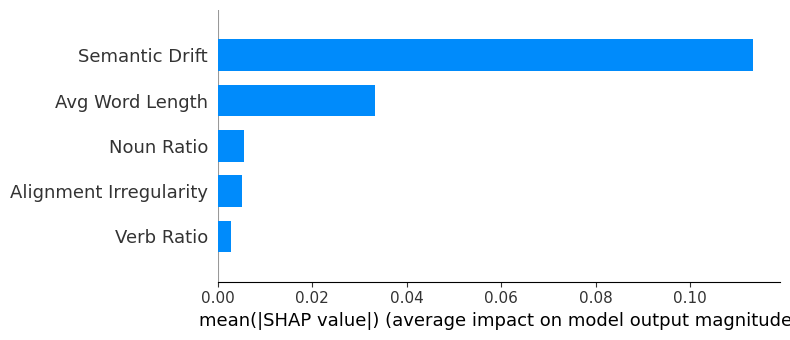

In [ ]:
shap.summary_plot(
    shap_values[:, :, 1], # Corrected: Selects SHAP values for the second class across all samples
    X_test_mm,
    feature_names=feature_names,
    plot_type="bar"
)

**Detailed SHAP Plot**

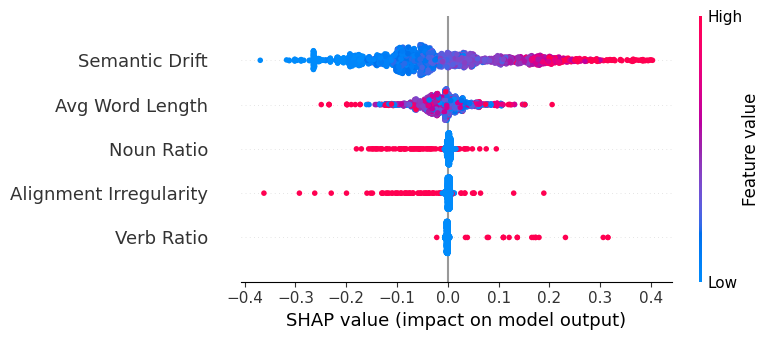

In [ ]:
shap.summary_plot(
    shap_values[:,:,1],
    X_test_mm,
    feature_names=feature_names
)

**Local Explanation**

In [ ]:
import shap
shap.initjs()

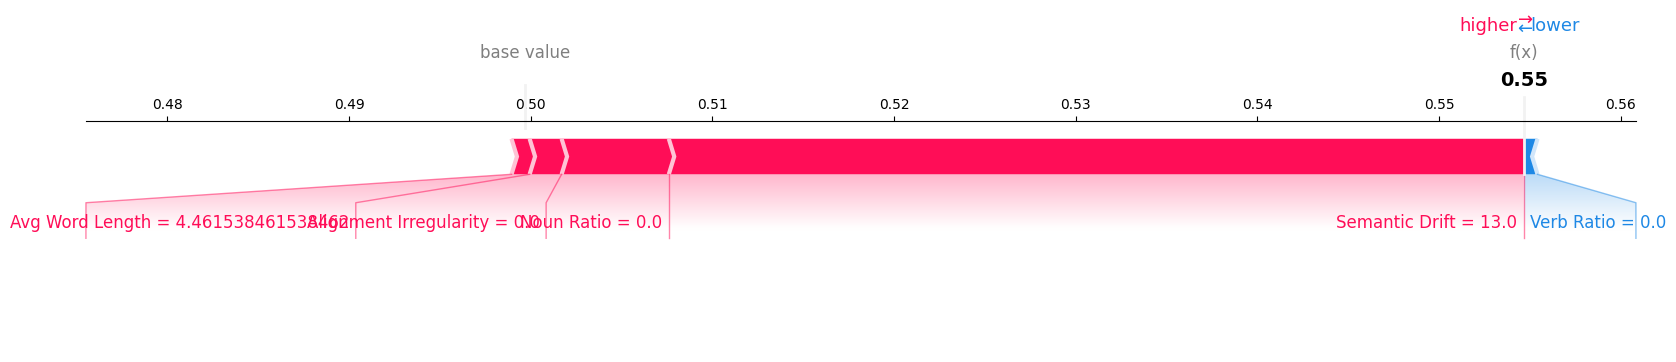

In [ ]:
idx = 25

shap.force_plot(
    explainer.expected_value[1], # Select the expected value for class 1
    shap_values[idx, :, 1],      # SHAP values for the 'idx' sample, for the second class (index 1)
    X_test_mm[idx],              # Feature values for the 'idx' sample from the numpy array X_test_mm
    feature_names=feature_names,
    matplotlib=True
)

# **Ablation Visualization**

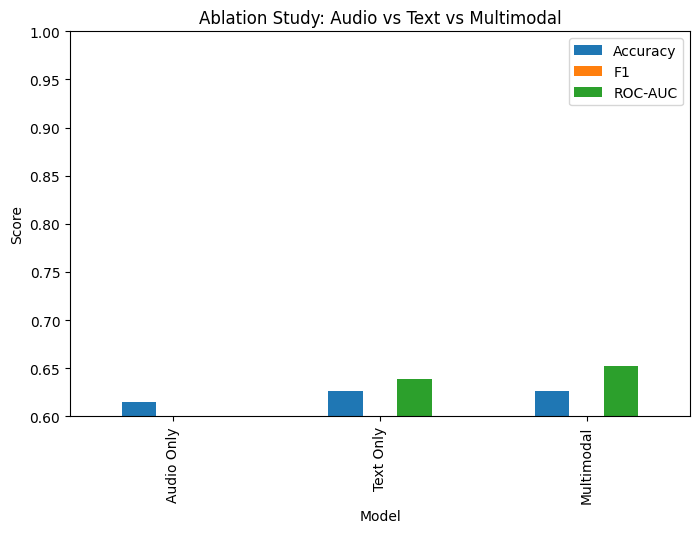

In [ ]:
import matplotlib.pyplot as plt

ablation_df.set_index("Model").plot(
    kind="bar",
    figsize=(8,5)
)
plt.ylim(0.6, 1.0)
plt.title("Ablation Study: Audio vs Text vs Multimodal")
plt.ylabel("Score")
plt.show()

# **Confidence Calibration**

**Getting the Probabilities**

In [ ]:
y_prob = clf_mm.predict_proba(X_test_mm)[:, 1]

**Reliability Curve**

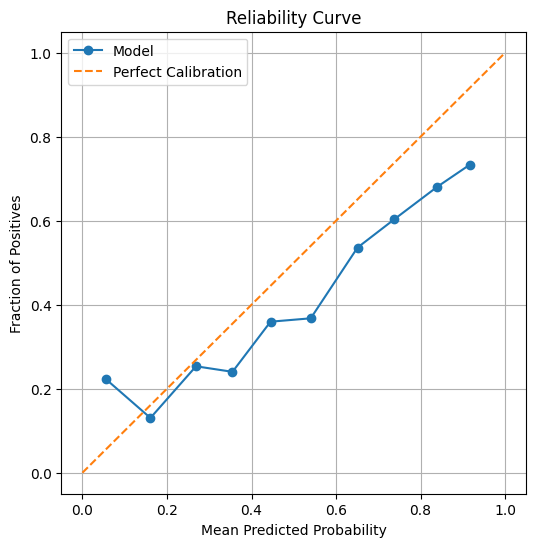

In [ ]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Re-obtain y_test_mm using the same split logic
# Need to use the full X and y and then select the multimodal features
# and get the corresponding y_test.

# Get the feature indices for 'Multimodal'
idx_mm = FEATURE_SETS["Multimodal"]
X_sub_mm = X[:, idx_mm]

# Perform the train-test split again to get y_test_mm
# We only need y_te here, so we can use placeholders for X_tr, X_te, y_tr
_, _, _, y_test_mm = train_test_split(
    X_sub_mm, y, test_size=0.2,
    stratify=y, random_state=RANDOM_SEED
)

prob_true, prob_pred = calibration_curve(
    y_test_mm, # Use the correctly derived y_test_mm
    y_prob,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(6,6))
plt.plot(prob_pred, prob_true, marker='o', label='Model')
plt.plot([0,1], [0,1], linestyle='--', label='Perfect Calibration')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Reliability Curve')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import brier_score_loss

brier_cal = brier_score_loss(y_test_mm, y_prob)
print(f"Brier Score (Before Calibration): {brier_cal:.4f}")

Brier Score (Before Calibration): 0.2289


In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split

# Get the feature indices for 'Multimodal'
idx_mm = FEATURE_SETS["Multimodal"]
X_sub_mm = X[:, idx_mm]

# Re-perform the train-test split for Multimodal features and labels
X_train_mm, X_test_mm_cal, y_train_mm, y_test_mm_cal = train_test_split(
    X_sub_mm, y, test_size=0.2,
    stratify=y, random_state=RANDOM_SEED
)

# Use the pre-trained RandomForestClassifier as the base estimator
# from the 'results' dictionary
clf_mm = results["Multimodal"][0]

calibrated_model = CalibratedClassifierCV(
    clf_mm, # Pass clf_mm as the first positional argument
    method='sigmoid',
    cv=3
)

# Fit the calibrated model on the training data
calibrated_model.fit(X_train_mm, y_train_mm)

# Predict calibrated probabilities on the test data
y_prob_cal = calibrated_model.predict_proba(X_test_mm_cal)[:, 1]

**Reliability Curve (After Calibration)**

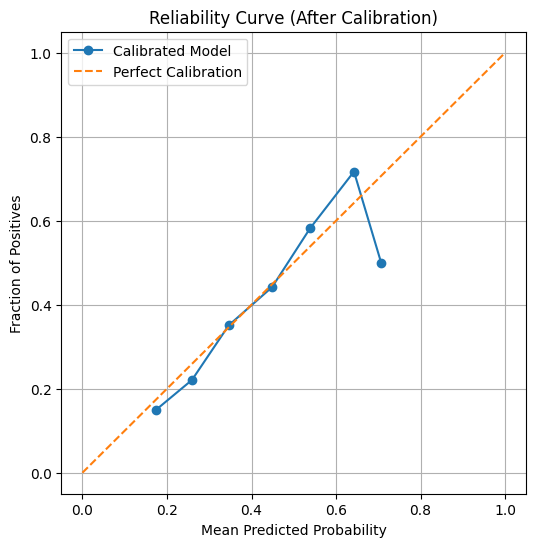

In [ ]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true_cal, prob_pred_cal = calibration_curve(
    y_test_mm_cal,
    y_prob_cal,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(6,6))
plt.plot(prob_pred_cal, prob_true_cal, marker='o', label='Calibrated Model')
plt.plot([0,1], [0,1], linestyle='--', label='Perfect Calibration')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Reliability Curve (After Calibration)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import brier_score_loss

brier_cal = brier_score_loss(y_test_mm_cal, y_prob_cal)
print(f"Brier Score (After Calibration): {brier_cal:.4f}")

Brier Score (After Calibration): 0.2173


# **Counterfactual Explanation**

In [ ]:
import numpy as np

# Get predictions from the multimodal classifier on the test set
y_pred = clf_mm.predict(X_test_mm)

# pick a sample predicted as fake
# Ensure that there is at least one fake prediction before trying to get its index
if 1 in y_pred:
    idx = np.where(y_pred == 1)[0][0]   # 1 = fake
else:
    print("No samples predicted as fake (class 1) in the test set.")
    # Handle this case, e.g., by picking a random sample or stopping
    idx = 0 # Fallback to first sample if no fake predictions

x_orig = X_test_mm[idx] # Corrected from X_test.iloc[idx].copy()
orig_prob = clf_mm.predict_proba([x_orig])[0, 1] # Corrected from model.predict_proba

print("Original fake probability:", orig_prob)

Original fake probability: 0.6406820765996677


In [ ]:
feature = "Avg Word Length"

In [ ]:
step = 0.02     # small change
max_change = 0.5

# Get the index of the feature from feature_names
feature_idx = feature_names.index(feature)

for delta in np.arange(0, max_change, step):
    x_cf = x_orig.copy()
    # Use the integer index to modify the feature value
    x_cf[feature_idx] += delta

    # Use clf_mm (the multimodal classifier) instead of model
    prob = clf_mm.predict_proba([x_cf])[0, 1]

    if prob < 0.5:   # prediction flips fake → real
        print(f"Prediction flipped at Δ{feature} = +{delta:.2f}")
        print("New fake probability:", prob)
        break

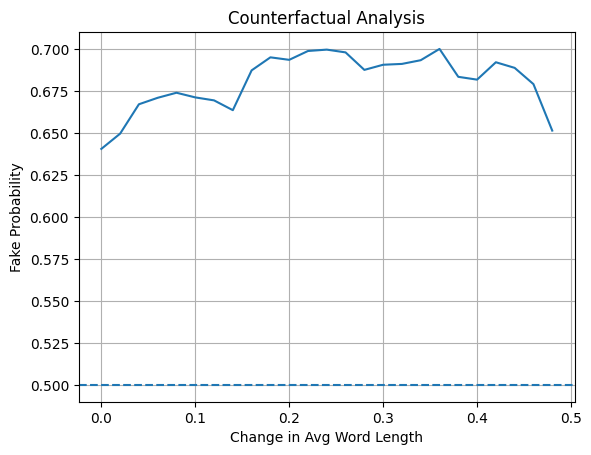

In [ ]:
deltas = []
probs = []

# Get the index of the feature from feature_names
feature_idx = feature_names.index(feature)

for delta in np.arange(0, max_change, step):
    x_cf = x_orig.copy()
    # Use the integer index to modify the feature value
    x_cf[feature_idx] += delta
    # Use clf_mm (the multimodal classifier) instead of model
    prob = clf_mm.predict_proba([x_cf])[0, 1]
    deltas.append(delta)
    probs.append(prob)

import matplotlib.pyplot as plt

plt.plot(deltas, probs)
plt.axhline(0.5, linestyle='--')
plt.xlabel(f"Change in {feature}")
plt.ylabel("Fake Probability")
plt.title("Counterfactual Analysis")
plt.grid(True)
plt.show()

# **Streamlit UI**

In [ ]:
!pip install -q streamlit cloudflared

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 91.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 128.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 kB 7.5 MB/s eta 0:00:00


In [ ]:
%%writefile app.py

import streamlit as st
import numpy as np
import pandas as pd
import shap
import joblib
import whisper
import librosa
import spacy
import nltk
import matplotlib.pyplot as plt

nltk.download("punkt")

# -----------------------------
# Page Config
# -----------------------------
st.set_page_config(
    page_title="Deepfake Speech Detection (NLP)",
    layout="centered"
)

st.title("🧠 NLP-based Deepfake Speech Detection")
st.write("Upload a **WAV audio file** to detect deepfake speech using linguistic cues.")

# -----------------------------
# Load NLP tools
# -----------------------------
@st.cache_resource
def load_nlp():
    return spacy.load("en_core_web_sm")

@st.cache_resource
def load_whisper():
    return whisper.load_model("base")

nlp = load_nlp()
whisper_model = load_whisper()

# -----------------------------
# Load Model
# -----------------------------
@st.cache_resource
def load_model():
    return joblib.load("model.pkl")

model = load_model()

# -----------------------------
# Feature Names (MATCH TRAINING)
# -----------------------------
feature_names = [
    "Semantic Drift",
    "Avg Word Length",
    "Noun Ratio",
    "Verb Ratio",
    "Alignment Irregularity"
]

# -----------------------------
# Feature Extraction Functions
# -----------------------------
def extract_features_from_text(text):
    doc = nlp(text)

    words = [token.text for token in doc if token.is_alpha]

    avg_word_len = np.mean([len(w) for w in words]) if words else 0

    noun_ratio = len([t for t in doc if t.pos_ == "NOUN"]) / len(doc) if len(doc) else 0
    verb_ratio = len([t for t in doc if t.pos_ == "VERB"]) / len(doc) if len(doc) else 0

    sentence_vectors = [sent.vector for sent in doc.sents if sent.has_vector]
    if len(sentence_vectors) > 1:
        semantic_drift = np.mean([
            np.linalg.norm(sentence_vectors[i] - sentence_vectors[i + 1])
            for i in range(len(sentence_vectors) - 1)
        ])
    else:
        semantic_drift = 0

    alignment_irregularity = np.std(
        [len(sent) for sent in doc.sents]
    ) if len(list(doc.sents)) else 0

    return [
        semantic_drift,
        avg_word_len,
        noun_ratio,
        verb_ratio,
        alignment_irregularity
    ]


# -----------------------------
# File Upload
# -----------------------------
uploaded_audio = st.file_uploader(
    "Upload WAV file",
    type=["wav"]
)

if uploaded_audio is not None:
    st.audio(uploaded_audio)

    with st.spinner("Transcribing audio..."):
        audio, sr = librosa.load(uploaded_audio, sr=16000)
        result = whisper_model.transcribe(audio)
        transcript = result["text"]

    st.subheader("📝 Transcribed Text")
    st.write(transcript)

    with st.spinner("Extracting NLP features..."):
        features = extract_features_from_text(transcript)
        X = np.array(features).reshape(1, -1)

    st.subheader("📌 Extracted Features")
    st.table(pd.DataFrame(X, columns=feature_names))

    # -----------------------------
    # Prediction
    # -----------------------------
    pred = model.predict(X)[0]
    prob = model.predict_proba(X)[0][1]

    st.subheader("🔍 Prediction Result")

    if pred == 1:
        st.error(f"⚠️ Deepfake Speech Detected (Confidence: {prob:.2f})")
    else:
        st.success(f"✅ Genuine Speech (Confidence: {1 - prob:.2f})")

    # -----------------------------
    # SHAP Explanation
    # -----------------------------
# -----------------------------
# Footer
# -----------------------------
st.markdown("---")
st.caption("NLP CA2 | Deepfake Speech Detection | WAV → NLP → ML → SHAP")

Overwriting app.py


In [ ]:
import pickle
with open("model.pkl", "wb") as f:
    pickle.dump(clf_mm, f)

In [ ]:
!wget https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64

--2026-02-09 12:10:38--  https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
Resolving github.com (github.com)... 140.82.112.3
Connecting to github.com (github.com)|140.82.112.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://github.com/cloudflare/cloudflared/releases/download/2026.2.0/cloudflared-linux-amd64 [following]
--2026-02-09 12:10:38--  https://github.com/cloudflare/cloudflared/releases/download/2026.2.0/cloudflared-linux-amd64
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/106867604/f9298ca8-89c8-41fe-a51f-e24cb2059878?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-02-09T12%3A48%3A11Z&rscd=attachment%3B+filename%3Dcloudflared-linux-amd64&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-02-09T1

In [ ]:
!chmod +x cloudflared-linux-amd64

In [ ]:
!mv cloudflared-linux-amd64 /usr/local/bin/cloudflared

In [ ]:
!cloudflared --version

cloudflared version 2026.2.0 (built 2026-02-06-14:47 UTC)


In [ ]:
!nohup streamlit run app.py \
  --server.port 8501 \
  --server.enableXsrfProtection false \
  --browser.gatherUsageStats false \
  > streamlit.log 2>&1 &

In [ ]:
!cloudflared tunnel --url http://localhost:8501

2026-02-09T12:10:54Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-02-09T12:10:54Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-02-09T12:10:57Z INF +--------------------------------------------------------------------------------------------+
2026-02-09T12:10:57Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-02-09T12:10:57Z INF |  https://liquid-referred-permitted-reminder.trycloudfl